# Einfache Lineare Regression

**Ziel:** Sie untersuchen den Zusammenhang zwischen **einer numerischen Eingabevariable** und **einer numerischen Zielvariable**, trainieren ein lineares Modell und bewerten dessen Vorhersagen.

**Für Advertising und Players sowie andere CSV-Dateien geeignet.** Sie müssen den Python-Code nicht vollständig verstehen: Ändern Sie nur die Werte in der **Konfigurationszelle** (Schritt 3) und führen Sie die Zellen nacheinander aus. Alle anderen Code-Zellen sind ausgeblendet – mit einem Doppelklick auf eine Zelle können Sie den Code bei Interesse einblenden.

**Modell:** $\hat y = \hat\beta_0 + \hat\beta_1 x$

## 1. Datensatz hochladen
**Was passiert hier?** Es öffnet sich ein Dialog, über den Sie eine CSV-Datei von Ihrem Computer in die Colab-Sitzung hochladen (z. B. `Advertising.csv` oder `players.csv`). Die Datei steht anschließend für alle weiteren Schritte zur Verfügung.

In [1]:
#@title 1. CSV-Datei hochladen
# Colab-Funktion zum Hochladen von Dateien importieren
from google.colab import files

# Upload-Dialog öffnen; Ergebnis ist ein Dictionary {Dateiname: Dateiinhalt (Bytes)}
uploaded = files.upload()

# Abbrechen mit verständlicher Meldung, falls keine Datei ausgewählt wurde
if not uploaded:
    raise ValueError('Bitte eine CSV-Datei auswählen.')

Saving Advertising.csv to Advertising.csv


## 2. Daten ansehen
**Was passiert hier?** Die hochgeladene CSV-Datei wird als Tabelle (DataFrame) eingelesen. Angezeigt werden die ersten fünf Zeilen, damit Sie die **Spaltennamen** sehen – diese benötigen Sie im nächsten Schritt für die Konfiguration.

In [2]:
#@title 2. Daten einlesen und anzeigen
import io
import pandas as pd
import numpy as np

# Name der hochgeladenen Datei ermitteln und Inhalt als DataFrame einlesen
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Eventuell mitexportierte Indexspalten ("Unnamed: 0") entfernen
df = df.loc[:, ~df.columns.astype(str).str.match(r'^Unnamed(:|$)')]

# Die ersten fünf Zeilen anzeigen
display(df.head())

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 3. Konfiguration – nur hier anpassen
**Was passiert hier?** Sie legen fest, welche Spalte als Eingabevariable `X_VARIABLE` und welche als Zielvariable `Y_VARIABLE` verwendet wird. Wählen Sie **genau eine** numerische Eingabevariable. Die Schreibweise muss exakt zu den Spaltennamen im Datensatz passen.

Advertising: `TV` → `sales`  ·  Players: z. B. `goalsTotal` → `marketvalue`.

Zusätzlich legen Sie fest, welcher Anteil der Daten als Testdaten zurückgehalten wird (`TEST_SIZE`) und mit welchem Startwert die zufällige Aufteilung erfolgt (`RANDOM_STATE`, damit alle dieselbe Aufteilung erhalten).

In [3]:
# ===== KONFIGURATION: NUR HIER ANPASSEN =====
X_VARIABLE = 'TV'            # Eingabevariable – Players-Beispiel: 'goalsTotal'
Y_VARIABLE = 'sales'         # Zielvariable    – Players-Beispiel: 'marketvalue'
TEST_SIZE = 0.20             # Anteil der Testdaten (0.20 = 20 %)
RANDOM_STATE = 42            # Startwert für die zufällige Aufteilung (reproduzierbar)
# ===========================================

**Konfiguration prüfen:** Die folgende Zelle kontrolliert Ihre Eingaben (Spalten vorhanden, numerisch, unterschiedlich) und entfernt Zeilen mit fehlenden Werten. Bei einem Fehler erhalten Sie einen Hinweis, was Sie in der Konfiguration korrigieren müssen.

In [ ]:
#@title 3b. Konfiguration prüfen und Daten vorbereiten
# Spaltennamen müssen als Text angegeben werden
if not isinstance(X_VARIABLE, str) or not isinstance(Y_VARIABLE, str):
    raise ValueError('Bitte für X_VARIABLE und Y_VARIABLE jeweils einen Spaltennamen als Text angeben.')

# Eingabe- und Zielvariable dürfen nicht identisch sein
if X_VARIABLE == Y_VARIABLE:
    raise ValueError('Eingabevariable und Zielvariable müssen unterschiedlich sein.')

# Prüfen, ob beide Spalten im Datensatz existieren
missing = [c for c in [X_VARIABLE, Y_VARIABLE] if c not in df.columns]
if missing:
    raise ValueError(f'Spalten nicht gefunden: {missing}. Vorhanden: {list(df.columns)}')

# Prüfen, ob beide Spalten numerisch sind (Regression braucht Zahlen)
non_numeric = [c for c in [X_VARIABLE, Y_VARIABLE] if not pd.api.types.is_numeric_dtype(df[c])]
if non_numeric:
    raise ValueError(f'Nicht numerische Spalten: {non_numeric}.')

# Nur die beiden benötigten Spalten behalten; unendliche und fehlende Werte entfernen
model_df = df[[X_VARIABLE, Y_VARIABLE]].replace([np.inf, -np.inf], np.nan).dropna().copy()
if len(model_df) < 10:
    raise ValueError('Zu wenige vollständige Beobachtungen (mindestens 10 erforderlich).')

# Zusammenfassung ausgeben
print(f'Eingabevariable: {X_VARIABLE}  |  Zielvariable: {Y_VARIABLE}')
print(f'Verwendbare Beobachtungen: {len(model_df)} (entfernt: {len(df)-len(model_df)})')

Eingabevariable: TV  |  Zielvariable: sales
Verwendbare Beobachtungen: 200 (entfernt: 0)


## 4. Zusammenhang erkunden
**Was passiert hier?** Jede Beobachtung wird als Punkt dargestellt: waagerecht der Wert der Eingabevariable, senkrecht der Wert der Zielvariable. Am Scatterplot erkennen Sie, ob ein **annähernd linearer Zusammenhang** plausibel ist.

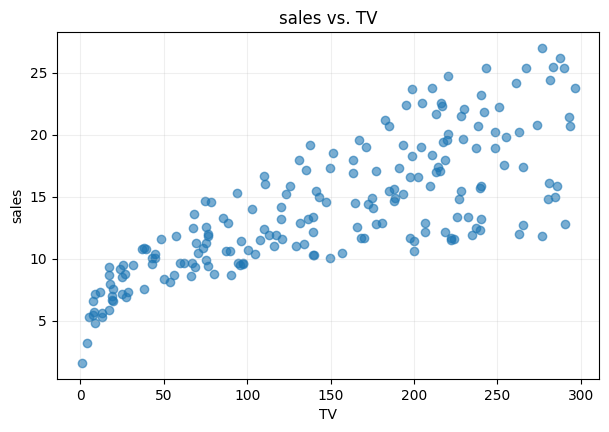

In [4]:
#@title 4. Scatterplot
import matplotlib.pyplot as plt

# Streudiagramm: Eingabevariable (x-Achse) gegen Zielvariable (y-Achse)
plt.figure(figsize=(7,4.5))
plt.scatter(model_df[X_VARIABLE], model_df[Y_VARIABLE], alpha=0.6)

# Achsenbeschriftungen, Titel und dezentes Gitter
plt.xlabel(X_VARIABLE)
plt.ylabel(Y_VARIABLE)
plt.title(f'{Y_VARIABLE} vs. {X_VARIABLE}')
plt.grid(alpha=0.2)
plt.show()

## 5. Trainings- und Testdaten bilden
**Was passiert hier?** Die Daten werden zufällig in **Trainingsdaten** und **Testdaten** aufgeteilt (Anteil gemäß `TEST_SIZE`). Die Regression wird ausschließlich mit den Trainingsdaten geschätzt. Die Testdaten dienen dazu, Vorhersagen auf unbekannten Beobachtungen zu bewerten.

In [5]:
#@title 5. Trainings- und Testdaten aufteilen
from sklearn.model_selection import train_test_split

# Eingabevariable X (doppelte Klammern: DataFrame, wie von scikit-learn erwartet) und Zielvariable y
X = model_df[[X_VARIABLE]]
y = model_df[Y_VARIABLE]

# Zufällige Aufteilung in Trainings- und Testdaten
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# Größe der beiden Teilmengen ausgeben
print('Training:', len(X_train), 'Beobachtungen')
print('Test:', len(X_test), 'Beobachtungen')

Training: 160 Beobachtungen
Test: 40 Beobachtungen


## 6. Lineare Regression trainieren
**Was passiert hier?** Das Modell wird mit den Trainingsdaten angepasst. Der Algorithmus bestimmt Achsenabschnitt $\hat\beta_0$ und Steigung $\hat\beta_1$, indem er den **Trainings-RSS** (Summe der quadrierten Abweichungen) minimiert. Ausgegeben wird die gelernte Regressionsfunktion.

In [6]:
#@title 6. Modell trainieren und Funktion anzeigen
from sklearn.linear_model import LinearRegression

# Lineares Regressionsmodell erstellen und mit den Trainingsdaten anpassen
model = LinearRegression()
model.fit(X_train, y_train)

# Geschätzte Koeffizienten und die daraus resultierende Funktion ausgeben
print(f'Achsenabschnitt (β₀): {model.intercept_:.5f}')
print(f'Steigung (β₁):        {model.coef_[0]:.5f}')
print(f'Gelernte Funktion: {Y_VARIABLE}_vorhergesagt = {model.intercept_:.5f} '
      f'{model.coef_[0]:+.5f} × {X_VARIABLE}')

Achsenabschnitt (β₀): 7.11964
Steigung (β₁):        0.04653
Gelernte Funktion: sales_vorhergesagt = 7.11964 +0.04653 × TV


## 7. Daten und Regressionsgerade darstellen
**Was passiert hier?** Trainings- und Testpunkte werden in unterschiedlichen Farben gezeichnet, zusammen mit der geschätzten Regressionsgerade. Die Gerade ist auf Basis der **Trainingsdaten** gelernt; die Testpunkte wurden nicht zum Schätzen verwendet.

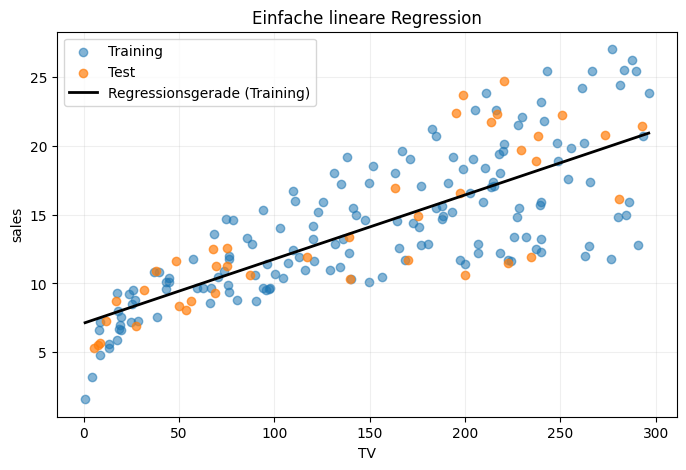

In [7]:
#@title 7. Datenpunkte und geschätzte Gerade
# 200 gleichmäßig verteilte x-Werte über den gesamten Wertebereich erzeugen
x_line = np.linspace(model_df[X_VARIABLE].min(), model_df[X_VARIABLE].max(), 200)
line_df = pd.DataFrame({X_VARIABLE: x_line})

# Für diese x-Werte die Modellvorhersage berechnen -> Punkte der Regressionsgerade
y_line = model.predict(line_df)

# Trainings- und Testpunkte sowie die Regressionsgerade zeichnen
plt.figure(figsize=(8,5))
plt.scatter(X_train[X_VARIABLE], y_train, alpha=0.55, label='Training')
plt.scatter(X_test[X_VARIABLE], y_test, alpha=0.7, label='Test')
plt.plot(x_line, y_line, color='black', linewidth=2, label='Regressionsgerade (Training)')

# Beschriftungen und Legende
plt.xlabel(X_VARIABLE)
plt.ylabel(Y_VARIABLE)
plt.title('Einfache lineare Regression')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 8. Vorhersagen auf Testdaten und Modellfehler
**Was passiert hier?** Das trainierte Modell sagt die Zielvariable für die Testdaten vorher. Eine Tabelle zeigt für die ersten zehn Testbeobachtungen Istwert, Vorhersage und **Residuum** (Ist − Vorhersage). Anschließend werden Fehlermaße auf den Testdaten berechnet:

**SSE/RSS:** Summe der quadrierten Fehler; **MSE:** mittlerer quadrierter Fehler; **RMSE:** Wurzel aus dem MSE – Fehlermaß in der Einheit der Zielvariable.

In [8]:
#@title 8. Testvorhersagen und Modellgüte
from sklearn.metrics import mean_squared_error

# Vorhersagen für die Testdaten berechnen
y_pred = model.predict(X_test)

# Vergleichstabelle: Eingabewert, Istwert, Vorhersage und Residuum
vergleich = X_test.copy()
vergleich['Istwert'] = y_test.to_numpy()
vergleich['Vorhersage'] = y_pred
vergleich['Residuum (Ist - Vorhersage)'] = vergleich['Istwert'] - vergleich['Vorhersage']
display(vergleich.head(10).round(3))

# Fehlermaße auf den Testdaten berechnen
mse = mean_squared_error(y_test, y_pred)                    # mittlerer quadrierter Fehler
rmse = np.sqrt(mse)                                         # Wurzel aus MSE (Einheit der Zielvariable)
sse = float(np.sum((y_test.to_numpy() - y_pred) ** 2))      # Summe der quadrierten Fehler

print(f'SSE/RSS = {sse:.3f}')
print(f'MSE     = {mse:.3f}')
print(f'RMSE    = {rmse:.3f}')
print('Alle Kennzahlen beziehen sich auf die Testdaten.')

,TV,Istwert,Vorhersage,Residuum (Ist - Vorhersage)
95,163.3,16.9,14.718,2.182
15,195.4,22.4,16.212,6.188
30,292.9,21.4,20.748,0.652
158,11.7,7.3,7.664,-0.364
128,220.3,24.7,17.370,7.330
115,75.1,12.6,10.614,1.986
69,216.8,22.3,17.207,5.093
170,50.0,8.4,9.446,-1.046
174,222.4,11.5,17.468,-5.968
45,175.1,14.9,15.267,-0.367


R²      = 0.677
MAE     = 2.444
MSE     = 10.205
RMSE    = 3.194
SSE/RSS = 408.186
Alle Kennzahlen beziehen sich auf die Testdaten.


## 9. Modellgüte visualisieren
**Was passiert hier?** Für jede Testbeobachtung wird der tatsächliche Wert (x-Achse) gegen den vorhergesagten Wert (y-Achse) aufgetragen. Je näher die Punkte an der gestrichelten Diagonale liegen, desto genauer stimmen Vorhersage und Istwert überein.

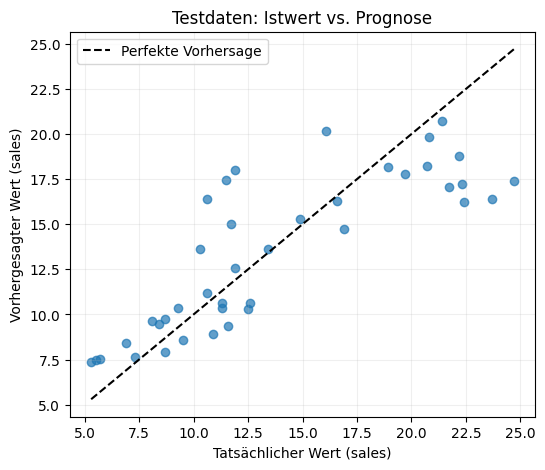

In [9]:
#@title 9. Istwerte und Vorhersagen vergleichen
# Istwerte gegen Vorhersagen der Testdaten zeichnen
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred, alpha=0.7)

# Diagonale y = x als Referenz für eine perfekte Vorhersage
lo = min(float(y_test.min()), float(np.min(y_pred)))
hi = max(float(y_test.max()), float(np.max(y_pred)))
plt.plot([lo,hi], [lo,hi], 'k--', label='Perfekte Vorhersage')

# Beschriftungen und Legende
plt.xlabel(f'Tatsächlicher Wert ({Y_VARIABLE})')
plt.ylabel(f'Vorhergesagter Wert ({Y_VARIABLE})')
plt.title('Testdaten: Istwert vs. Prognose')
plt.legend()
plt.grid(alpha=0.2)
plt.show()